In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

In [ ]:
diabetes = pd.read_csv("pima-indians-diabetes.csv")
diabetes.head()

## Let's do a quick check of null and type counts for the data, to see if cleaning is necessary.

In [ ]:
# Count duplicate rows, amount of nulls in each column
duplicate_rows = diabetes.duplicated().sum()
print("Duplicates rows:", duplicate_rows)

null_counts = diabetes.isnull().sum()
print(null_counts)

In [ ]:
# Check data type percentages for each column
dtype_percentages = pd.DataFrame({
    col: diabetes[col].apply(lambda x: type(x).__name__).value_counts(normalize=True) * 100
    for col in diabetes.columns
}).T.fillna(0)

dtype_percentages

## Data appears clean, so no cleaning is necessary in this case.

# We're going to go through 3 different data balancing techniques: Random Undersampling, Random Oversampling, and SMOTE.

In [ ]:
# Split the data into features (X) and our target variable (y)

X = diabetes.drop('Class', axis=1)
y = diabetes['Class']

# Perform 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

First, we want to check if our data is even unbalanced.

We can use **.value_counts()** to produce the counts of each class, and visualize it with a bar chart.

In [ ]:
# Bar chart counting the instances of each class
plt.figure(figsize=(5, 5))
plt.bar(y_train.value_counts().index, y_train.value_counts())
plt.xticks(y_train.value_counts().index, y_train.value_counts().index)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

We can see from the class distribution that our data is fairly balanced, with about a 2:1 ratio between the classes.

# Random Undersampling

Random Undersampling works by randomly choosing instances of the majority class, and removing them from the dataset, until both classes are of equal count.

- **RandomUnderSampler()** : creates the RandomUnderSampler
- **sampling_strategy** : which class the sampler will remove/add
- **.fit_resample()** : fits sampler to the data, and resamples automatically

**What major problem do you see with Random Undersampling?**

In [ ]:
# Create the RandomUnderSampler
undersample = RandomUnderSampler(sampling_strategy='majority', random_state=42)
# Fit and resample the data with Undersampler
X_under, y_under = undersample.fit_resample(X_train, y_train)

# Print counts before and after undersampling
print("Before undersampling:")
print(y_train.value_counts())

print("\nAfter undersampling:")
print(y_under.value_counts())

In [ ]:
# Bar chart comparing counts of each class after Random Undersampling
plt.figure(figsize=(5, 5))
plt.bar(y_under.value_counts().index, y_under.value_counts())
plt.xticks(y_under.value_counts().index, y_under.value_counts().index)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Random Oversampling

Random Oversampling works by randomly choosing instances of the minority class, then duplicating and adding them to the dataset, until both classes are of equal count.

- **RandomOverSampler()** : creates the RandomOverSampler
- **sampling_strategy** : which class the sampler will remove/add
- **.fit_resample()** : fits sampler to the data, and resamples automatically

**What major problem do you see with Random Oversampling?**

In [ ]:
# Create the RandomOverSampler
oversample = RandomOverSampler(sampling_strategy='minority', random_state=42)
# Fit and resample the data with Oversampler
X_over, y_over = oversample.fit_resample(X_train, y_train)

# Print class counts before and after oversampling
print("Before oversampling:")
print(y_train.value_counts())

print("\nAfter oversampling:")
print(y_over.value_counts())

In [ ]:
# Bar chart comparing counts of each class after Random Oversampling
plt.figure(figsize=(5, 5))
plt.bar(y_over.value_counts().index, y_over.value_counts())
plt.xticks(y_over.value_counts().index, y_over.value_counts().index)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [ ]:
# Compare duplicate row counts for Original, Random Undersampling, and Random Oversampling
print("Original duplicate rows:", X_train.duplicated().sum())
print("Undersampled duplicate rows:", X_under.duplicated().sum())
print("Oversampled duplicate rows:", X_over.duplicated().sum())

# Synthetic Minority Oversampling Technique (SMOTE)

SMOTE is similar to Random Oversampling, but instead of duplicating rows of the minority class, it creates new, synthetic data with minority class labels. For a selected instance, SMOTE finds nearest neighbors, chooses one, and creates a new data point along the line between the original instance and its neighbor.

- **SMOTE()** : creates the SMOTE sampler
- **.fit_resample()** : fits sampler to the data, and resamples automatically

- **SMOTENC()** : creates a SMOTE sampler that can handle of mix of numerical and categorical features, **we will use this for the competition dataset**
- **SMOTENC()** requires a list of categorical features by their index


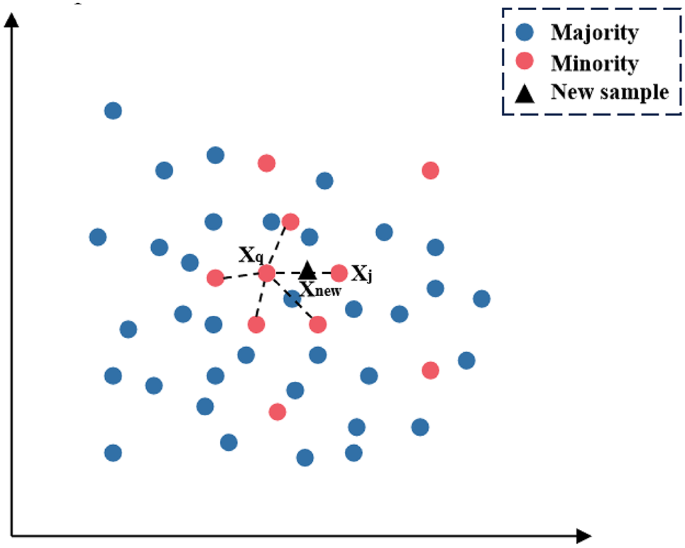

In [ ]:
# Create the SMOTE sampler
smote = SMOTE(sampling_strategy='auto', random_state=42)
# Fit and resample the data with SMOTE sampler
X_smote, y_smote = smote.fit_resample(X_train, y_train)

# Print class counts before and after SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_smote.value_counts())

In [ ]:
# Bar chart comparing counts of each class after SMOTE
plt.figure(figsize=(5, 5))
plt.bar(y_smote.value_counts().index, y_smote.value_counts())
plt.xticks(y_smote.value_counts().index, y_smote.value_counts().index)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [ ]:
# Compare duplicate row counts for all 4 situations
print("Original duplicate rows:", X_train.duplicated().sum())
print("Oversampled duplicate rows:", X_over.duplicated().sum())
print("Undersampled duplicate rows:", X_under.duplicated().sum())
print("SMOTE duplicate rows:", X_smote.duplicated().sum())


In [ ]:
# Create dataframe with class counts for each situation
distribution_comparison = pd.DataFrame({
    'Original': y_train.value_counts(),
    'Random Oversampling': y_over.value_counts(),
    'Random Undersampling': y_under.value_counts(),
    'SMOTE': y_smote.value_counts()
})

# Grouped bar chart comparing class counts for each situation
plt.figure(figsize=(10, 10))
distribution_comparison.plot(kind='bar', stacked=False)
plt.title('Class Distribution Comparison')
plt.xlabel('Class')
plt.ylabel('Count')
plt.legend(title='Sampling Method', bbox_to_anchor=(1.05, 1))
plt.show()

As we can see, SMOTE gives the best of both worlds, creating equal class counts but still avoiding significant loss of data (like in undersampling) and lots of duplicate rows (like in oversampling).

In [ ]:
# Create side-by-side boxplots for a few features to compare sampling techniques
datasets = {
    "Original": X_train,
    "Oversampled": X_over,
    "Undersampled": X_under,
    "SMOTE": X_smote
}

plot_data = pd.concat(
    [
        df.assign(Dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Features we will create boxplots for
features = ["Glucose", "BloodPressure", "Insulin", "BMI"]

# Create 2 x 2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=plot_data,
        x="Dataset",
        y=feature,
        order=["Original", "Oversampled", "Undersampled", "SMOTE"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

## When we get into evaluation metrics and modeling in the future, you will be able to see a difference in the predictions of models trained on balanced versus unbalanced data.